In [1]:
import torch
import torch.nn as nn
from torchvision import datasets,transforms
from torch.utils.data import DataLoader

In [2]:
print("Cuda available: ",torch.cuda.is_available())

Cuda available:  True


In [3]:
if torch.cuda.is_available():
    print("GPU: ",torch.cuda.get_device_name(0))

GPU:  NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [4]:
DATASET_PATH = r'D:\Plant_Disease_Classifier\dataset\raw\Plant_Disease_Detection'
IMG_SIZE = 224
BATCH_SIZE = 32


In [5]:
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE,IMG_SIZE)),
    transforms.ToTensor()
])
val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE,IMG_SIZE)),
    transforms.ToTensor()
])

In [6]:
dataset = datasets.ImageFolder(
    DATASET_PATH,transform = train_transform
)
print("Number of Images: ",len(dataset))
print("Number of classes: ",len(dataset.classes))

Number of Images:  35725
Number of classes:  23


In [7]:
for i,class_name in enumerate(dataset.classes):
    print(i,class_name)

0 Apple___Apple_scab
1 Apple___Black_rot
2 Apple___Cedar_apple_rust
3 Apple___healthy
4 Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
5 Corn_(maize)___Common_rust_
6 Corn_(maize)___Northern_Leaf_Blight
7 Corn_(maize)___healthy
8 Pepper__bell___Bacterial_spot
9 Pepper__bell___healthy
10 Potato___Early_blight
11 Potato___Late_blight
12 Potato___healthy
13 Tomato_Bacterial_spot
14 Tomato_Early_blight
15 Tomato_Late_blight
16 Tomato_Leaf_Mold
17 Tomato_Septoria_leaf_spot
18 Tomato_Spider_mites_Two_spotted_spider_mite
19 Tomato__Target_Spot
20 Tomato__Tomato_YellowLeaf__Curl_Virus
21 Tomato__Tomato_mosaic_virus
22 Tomato_healthy


In [8]:
from torch.utils.data import random_split
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset,val_dataset = random_split(dataset,[train_size,val_size],generator = torch.Generator().manual_seed(42))
print("Training images: ",len(train_dataset))
print("Validation images: ",len(val_dataset))

Training images:  28580
Validation images:  7145


In [9]:
train_loader = DataLoader(train_dataset,batch_size = BATCH_SIZE,shuffle = True)
val_loader = DataLoader(val_dataset,batch_size = BATCH_SIZE,shuffle = False)

In [10]:
images,labels = next(iter(train_loader))
print("Image shape: ",images.shape)
print("Label shape: ",labels.shape)

Image shape:  torch.Size([32, 3, 224, 224])
Label shape:  torch.Size([32])


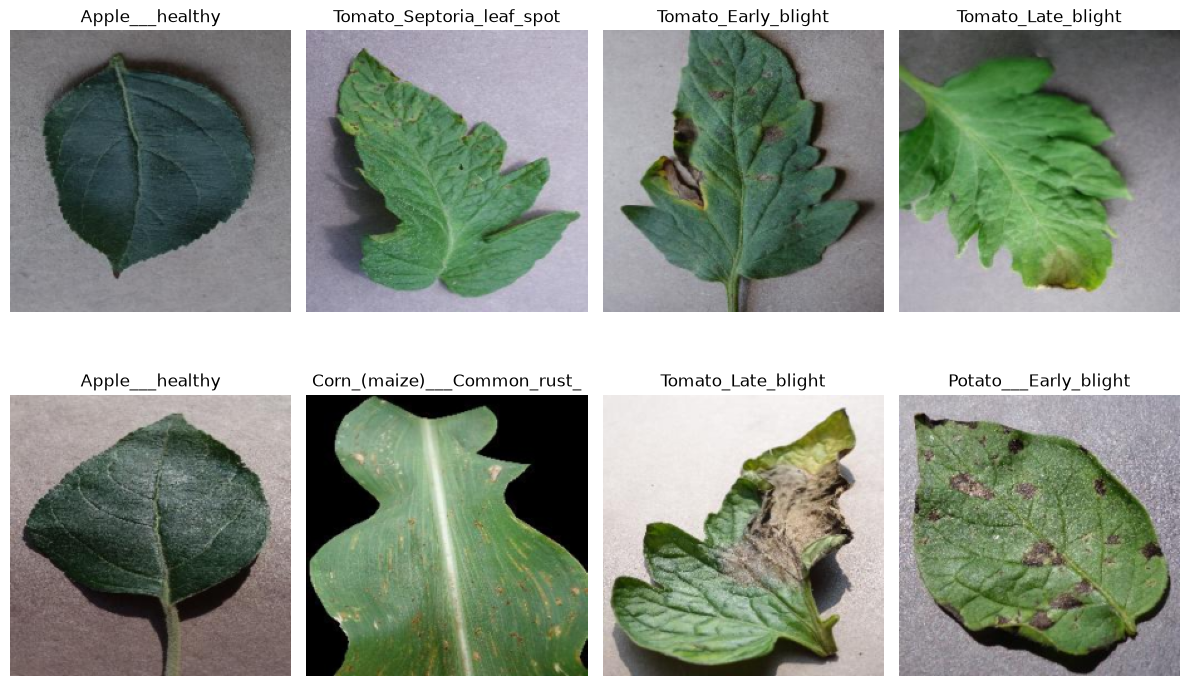

In [11]:
import matplotlib.pyplot as plt
images,labels = next(iter(train_loader))
plt.figure(figsize = (12,8))
for i in range(8):
    plt.subplot(2,4,i+1)
    image = images[i].permute(1,2,0)
    plt.imshow(image)
    plt.title(dataset.classes[labels[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

In [12]:
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

In [13]:
indices = list(range(len(dataset)))
labels = [dataset.targets[i] for i in indices]
train_indices,temp_indices = train_test_split(indices,test_size = 0.3,stratify = labels,random_state = 42)
temp_labels = [labels[i] for i in temp_indices]
val_indices,test_indices = train_test_split(temp_indices,test_size = 0.5,stratify = temp_labels,random_state = 42)
print("Training images: ",len(train_indices))
print("validation images: ",len(val_indices))
print("Test Images: ",len(test_indices))

Training images:  25007
validation images:  5359
Test Images:  5359


In [14]:
train_dataset = Subset(dataset,train_indices)
val_dataset = Subset(dataset,val_indices)
test_dataset = Subset(dataset,test_indices)

In [15]:
from torch.utils.data import DataLoader
train_loader = DataLoader(train_dataset,batch_size = BATCH_SIZE,shuffle = True)
val_loader = DataLoader(val_dataset,batch_size = BATCH_SIZE,shuffle = False)
test_loader = DataLoader(test_dataset,batch_size = BATCH_SIZE,shuffle = False)

In [16]:
images,labels = next(iter(train_loader))
print("Image batch shape: ",images.shape)
print("Label batch shape: ",labels.shape)

Image batch shape:  torch.Size([32, 3, 224, 224])
Label batch shape:  torch.Size([32])


In [17]:
num_classes = len(dataset.classes)
print("Number of classes: ",num_classes)
print("Class Names: ")
for i,class_name in enumerate(dataset.classes):
    print(i,class_name)

Number of classes:  23
Class Names: 
0 Apple___Apple_scab
1 Apple___Black_rot
2 Apple___Cedar_apple_rust
3 Apple___healthy
4 Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
5 Corn_(maize)___Common_rust_
6 Corn_(maize)___Northern_Leaf_Blight
7 Corn_(maize)___healthy
8 Pepper__bell___Bacterial_spot
9 Pepper__bell___healthy
10 Potato___Early_blight
11 Potato___Late_blight
12 Potato___healthy
13 Tomato_Bacterial_spot
14 Tomato_Early_blight
15 Tomato_Late_blight
16 Tomato_Leaf_Mold
17 Tomato_Septoria_leaf_spot
18 Tomato_Spider_mites_Two_spotted_spider_mite
19 Tomato__Target_Spot
20 Tomato__Tomato_YellowLeaf__Curl_Virus
21 Tomato__Tomato_mosaic_virus
22 Tomato_healthy


In [18]:
import torch
import torch.nn as nn
import torch.nn.functional as F
class PlantDiseaseCNN(nn.Module):
            def __init__(self, num_classes):
                super().__init__()
                self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
                self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
                self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
                self.pool = nn.MaxPool2d(2, 2)
                self.fc1 = nn.Linear(128 * 28 * 28, 256)
                self.dropout = nn.Dropout(0.5)
                self.fc2 = nn.Linear(256, num_classes)

            def forward(self, x):
                x = self.pool(F.relu(self.conv1(x)))
                x = self.pool(F.relu(self.conv2(x)))
                x = self.pool(F.relu(self.conv3(x)))
                x = torch.flatten(x, start_dim=1)
                x = F.relu(self.fc1(x))
                x = self.dropout(x)
                return self.fc2(x)

In [19]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model  = PlantDiseaseCNN(num_classes).to(device)
print("Device: ",device)
print("Model: ",model)

Device:  cuda
Model:  PlantDiseaseCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=100352, out_features=256, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=256, out_features=23, bias=True)
)


In [20]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(),lr = 0.001)
print("Loss Function: ",criterion)
print("Optimizer: ",optimizer)

Loss Function:  CrossEntropyLoss()
Optimizer:  Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [44]:
num_epochs = 5
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for images,labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs,labels)
        loss.backward()
        optimizer.step()
        running_loss +=loss.item()
        predictions = outputs.argmax(dim = 1)
        total += labels.size(0)
        correct += (predictions == labels).sum().item()
    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = 100 * correct / total
    print(
        f"Epoch [{epoch+1}/{num_epochs}]"
        f"Loss: {epoch_loss:.4f}"
        f"Accuracy: {epoch_accuracy:.2f}%"
    )

Epoch [1/5]Loss: 1.3536Accuracy: 57.43%
Epoch [2/5]Loss: 0.6816Accuracy: 78.11%
Epoch [3/5]Loss: 0.4825Accuracy: 84.05%
Epoch [4/5]Loss: 0.3575Accuracy: 88.19%
Epoch [5/5]Loss: 0.2820Accuracy: 90.61%


In [22]:
import copy
import torch
num_epochs = 20
best_val_accuracy = 0.0
best_model_weights = copy.deepcopy(model.state_dict())
for epoch in range(num_epochs):
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0
    for images,labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs,labels)
        loss.backward()
        optimizer.step()
        train_loss +=loss.item()
        predictions = outputs.argmax(dim = 1)
        train_total += labels.size(0)
        train_correct += (predictions == labels).sum().item()
    train_loss /= len(train_loader)
    train_accuracy = 100 * train_correct / train_total
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    with torch.no_grad():
        for images,labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)
            outputs = model(images)
            loss = criterion(outputs,labels)
            val_loss +=loss.item()
            predictions = outputs.argmax(dim = 1)
            val_total +=labels.size(0)
            val_correct += (predictions == labels).sum().item()
    val_loss /= len(val_loader)
    val_accuracy = 100 * val_correct/val_total
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_model_state = copy.deepcopy(model.state_dict())
    print(
        f"Epoch [{epoch+1}/{num_epochs}]"
        f"Train Loss: {train_loss:.4f}"
        f"Train Acc: {train_accuracy: .2f}%"
        f"Val_acc: {val_accuracy: .2f}"
        f"Val Loss: {val_loss:.4f}"
    )
model.load_state_dict(best_model_state)
print(f"\nBest Validation Accuracy; {best_val_accuracy:.2f}%")
            

Epoch [1/20]Train Loss: 1.2781Train Acc:  60.10%Val_acc:  79.19Val Loss: 0.6313
Epoch [2/20]Train Loss: 0.6150Train Acc:  79.92%Val_acc:  86.47Val Loss: 0.4104
Epoch [3/20]Train Loss: 0.4296Train Acc:  85.80%Val_acc:  90.07Val Loss: 0.2994
Epoch [4/20]Train Loss: 0.3288Train Acc:  89.27%Val_acc:  90.50Val Loss: 0.2793
Epoch [5/20]Train Loss: 0.2668Train Acc:  90.95%Val_acc:  90.91Val Loss: 0.2750
Epoch [6/20]Train Loss: 0.2155Train Acc:  92.81%Val_acc:  90.82Val Loss: 0.2968
Epoch [7/20]Train Loss: 0.1788Train Acc:  93.94%Val_acc:  90.46Val Loss: 0.3044
Epoch [8/20]Train Loss: 0.1613Train Acc:  94.58%Val_acc:  91.36Val Loss: 0.2908
Epoch [9/20]Train Loss: 0.1476Train Acc:  95.07%Val_acc:  93.28Val Loss: 0.2238
Epoch [10/20]Train Loss: 0.1172Train Acc:  96.15%Val_acc:  92.05Val Loss: 0.2887
Epoch [11/20]Train Loss: 0.1077Train Acc:  96.49%Val_acc:  93.25Val Loss: 0.2544
Epoch [12/20]Train Loss: 0.1117Train Acc:  96.32%Val_acc:  92.78Val Loss: 0.2909
Epoch [13/20]Train Loss: 0.1032Train 

In [21]:
num_classes = 23
model = PlantDiseaseCNN(num_classes)
model.load_state_dict(
    torch.load(r'D:\Plant_Disease_Classifier\notebooks\models\plant_disease_model.pth',
     map_location = device,
     weights_only = True
    )
)
model = model.to(device)
model.eval()
print("Trained model loaded successfully.")
print("Devices: ",device)

Trained model loaded successfully.
Devices:  cuda


In [23]:
from sklearn.metrics import classification_report,confusion_matrix
import numpy as np
model.eval()
all_predictions = []
all_labels = []
with torch.no_grad():
    for images,labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        predictions = outputs.argmax(dim = 1)
        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())
print(
    classification_report(all_labels,all_predictions,labels = list(range(num_classes)),target_names = dataset.classes,zero_division = 0)
)

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.00      0.00      0.00       302
                                 Apple___Black_rot       0.00      0.00      0.00       298
                          Apple___Cedar_apple_rust       0.00      0.00      0.00       264
                                   Apple___healthy       0.00      0.00      0.00       301
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.00      0.00      0.00       246
                       Corn_(maize)___Common_rust_       0.00      0.00      0.00       286
               Corn_(maize)___Northern_Leaf_Blight       0.00      0.00      0.00       286
                            Corn_(maize)___healthy       0.04      0.58      0.08       279
                     Pepper__bell___Bacterial_spot       0.00      0.00      0.00       149
                            Pepper__bell___healthy       0.00      0.00      0.

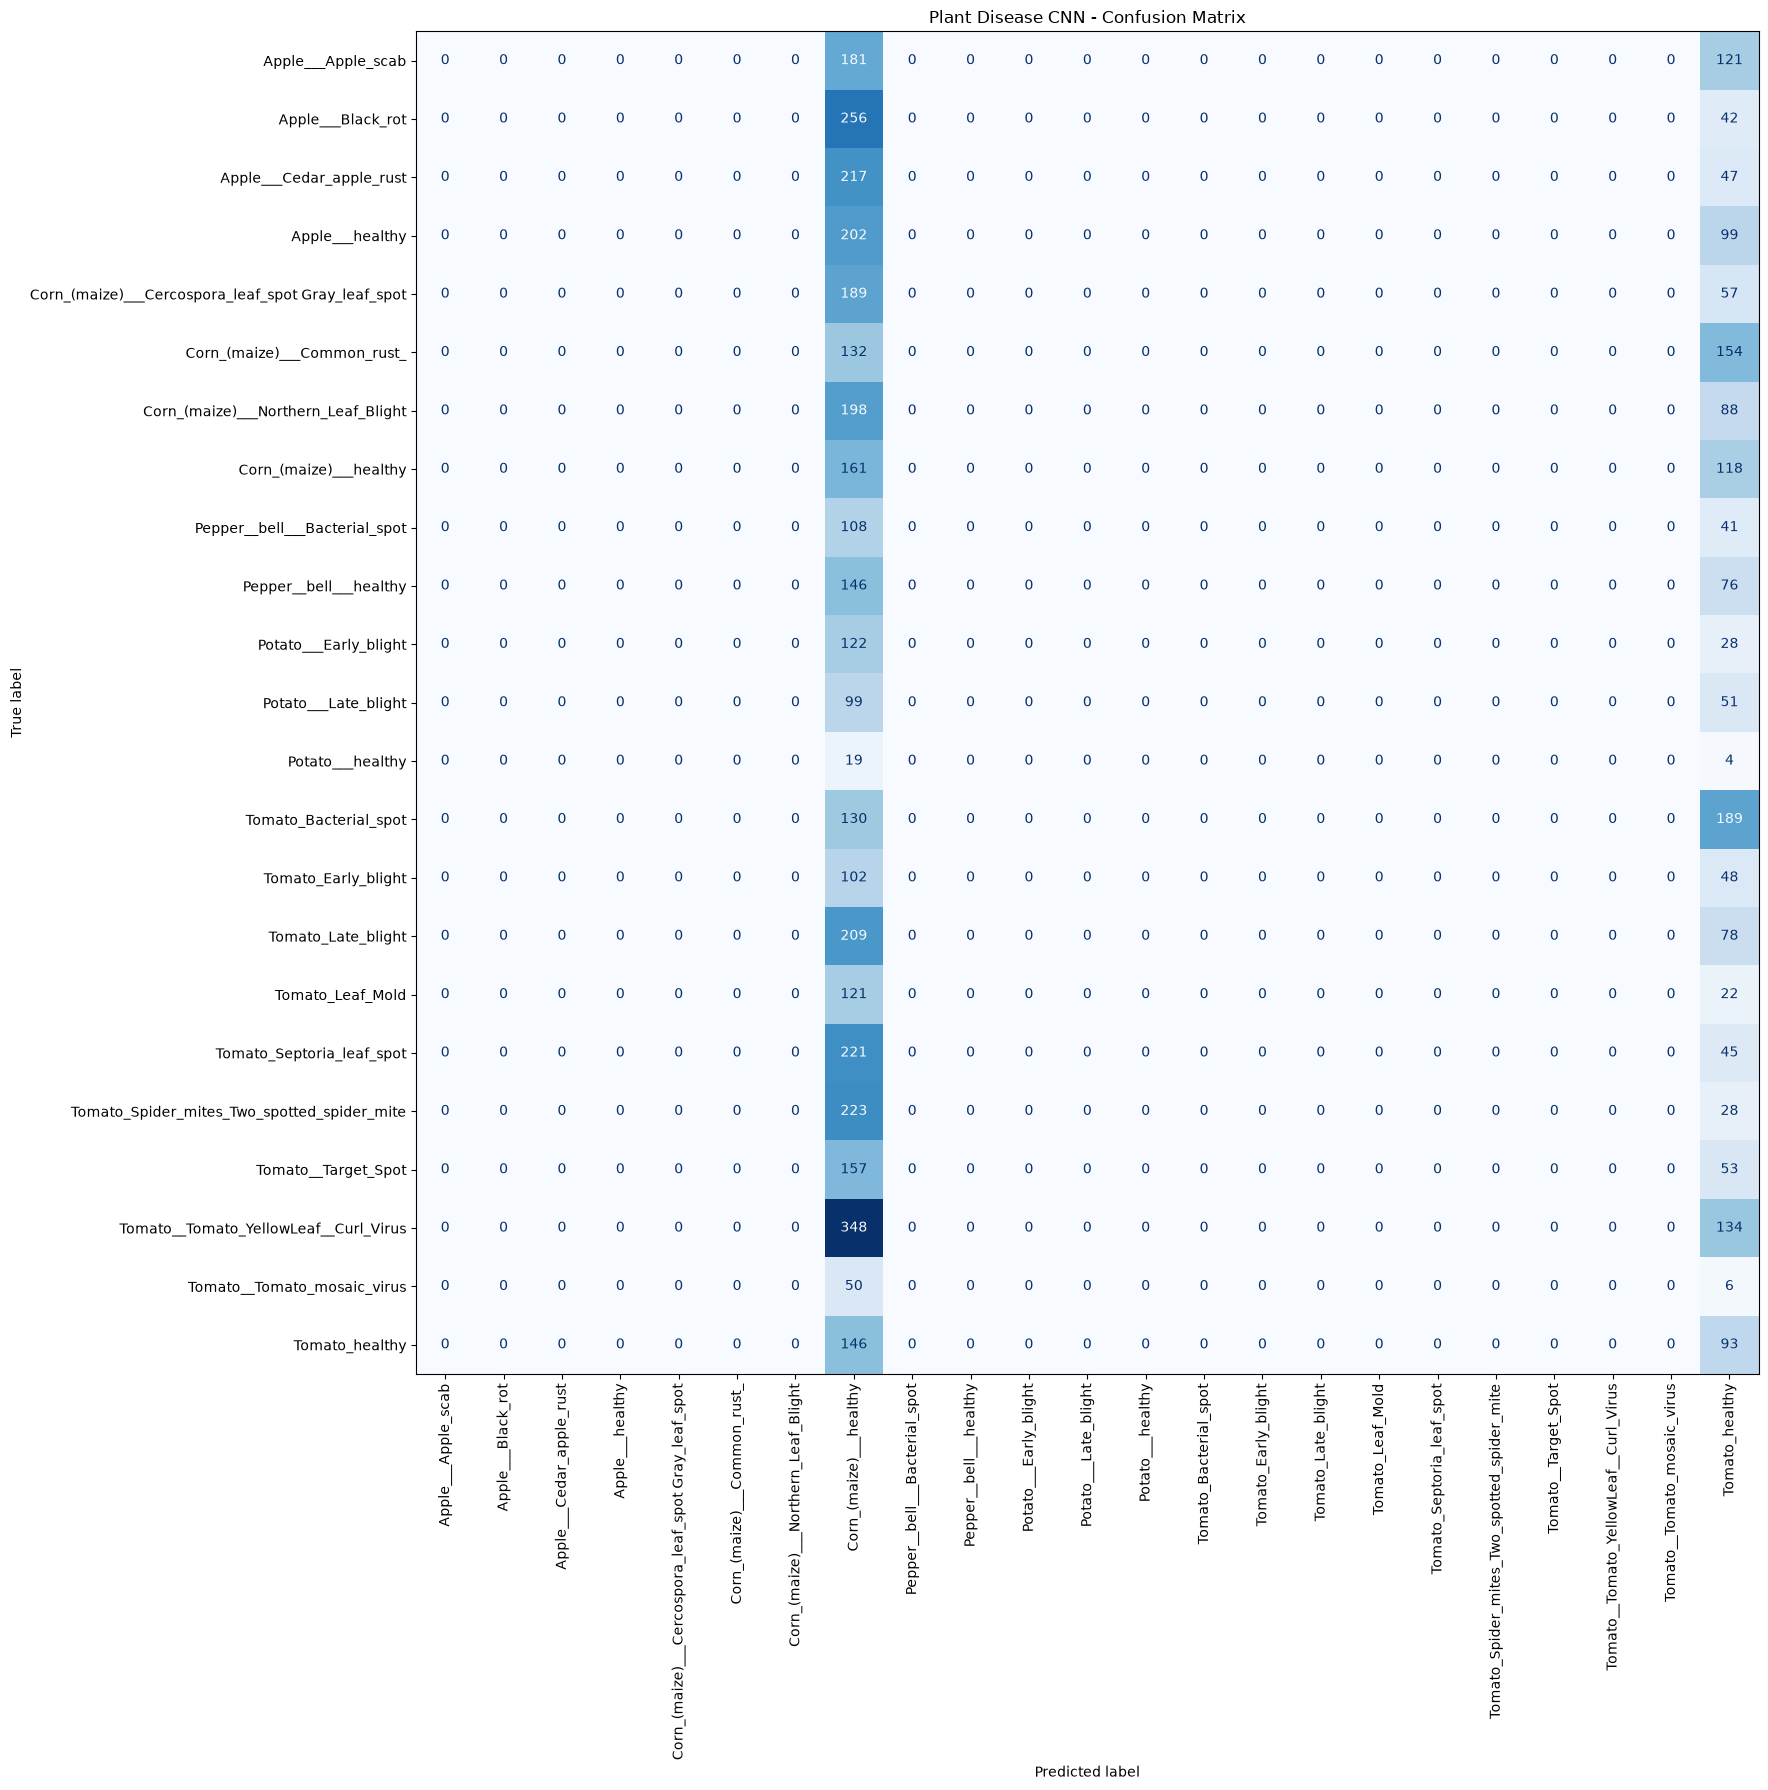

In [25]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels = list(range(num_classes))
)
fig,ax = plt.subplots(figsize = (18,18))
display = ConfusionMatrixDisplay(confusion_matrix = cm,
    display_labels = dataset.classes)
display.plot(
    ax = ax,
    xticks_rotation=90,
    cmap = "Blues",
    colorbar = False
)
plt.title("Plant Disease CNN - Confusion Matrix")
plt.tight_layout()
plt.show()